Importing libraries and downloading data

In [2]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#import Libraries for data Loading , Preprocessing , modeling and evalution
# Dataset (Benchmark Iris)& Preprocessing
from sklearn.datasets import load_iris
# To split data into training & Testing sets
from sklearn.model_selection import train_test_split
# To Normalize & Scale Features
from sklearn.preprocessing import StandardScaler

In [4]:
# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier


In [5]:
# Evalutions Metrices
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
# Visulization Utilities (To create custom colormaps for decision boundary plots)
from matplotlib.colors import ListedColormap

**Download Dataset**

In [6]:
#Chart appearance counter
sns.set_theme(style="whitegrid")
#Iris data
Iris=load_iris()
x=Iris.data
y=Iris.target

In [13]:
# Transform to Pandas DataFrame
df = pd.DataFrame(x, columns=Iris.feature_names)
df["target"] = y
df["target_name"] = df["target"].map({0: Iris.target_names[0], 1: Iris.target_names[1], 2: Iris.target_names[2]})
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Exploratory Data Analysis

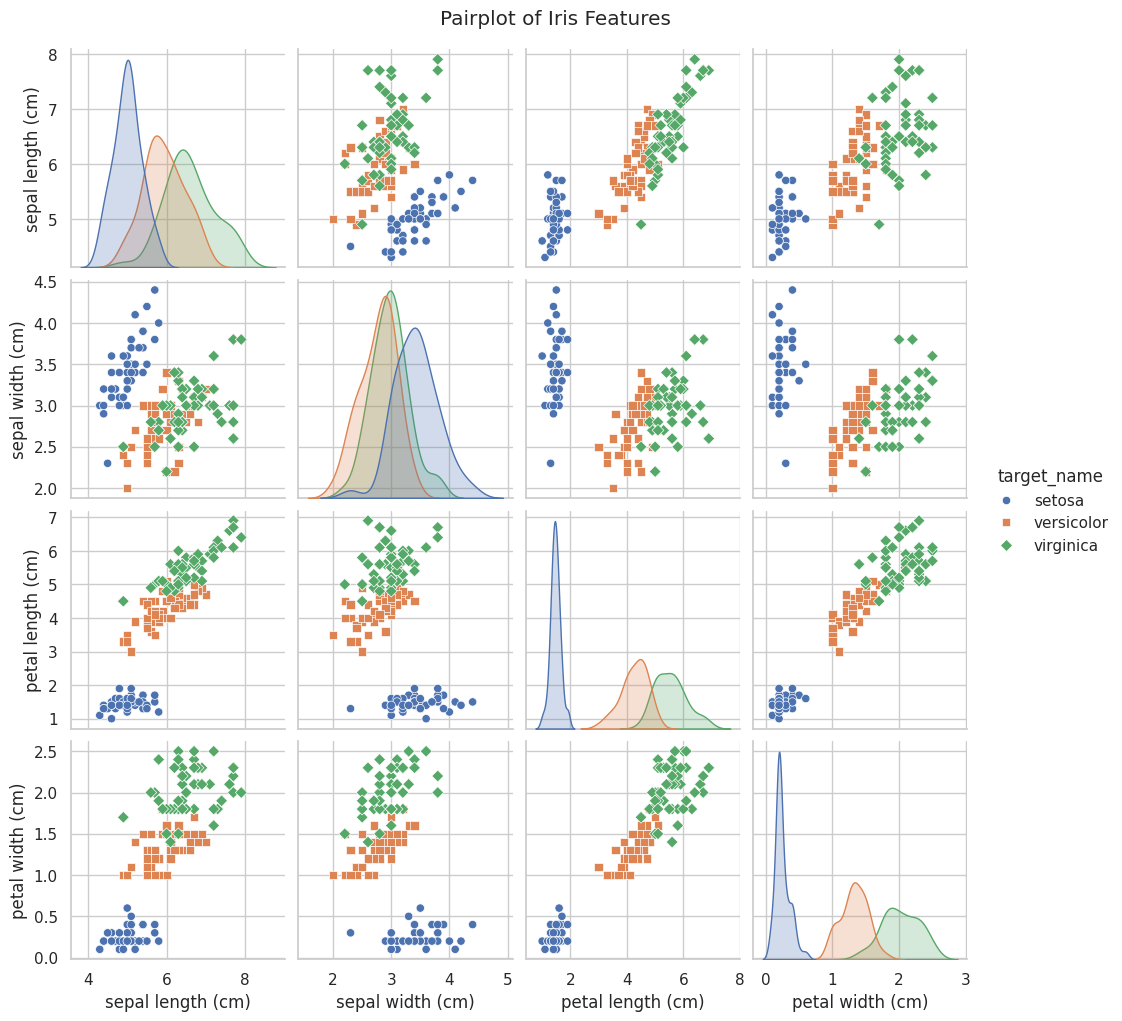

In [15]:
# Using Pairplot to Discover  relshionships between different properties
sns.pairplot(df.drop(columns=['target']),hue='target_name',markers=['o','s','D'])
plt.suptitle("Pairplot of Iris Features" , y=1.02)
plt.show()

(Train/Test Split & Scaling)

In [16]:
# Train / Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42,stratify=y)


In [18]:
# scaling features by using StanderdScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

print(f"Shape of x_train: {x_train.shape}")
print(f"Shape of x_test: {x_test.shape}")

Shape of x_train: (120, 4)
Shape of x_test: (30, 4)


(Training & Evalution)

In [22]:
# Training Logistic Regression
log_reg = LogisticRegression(random_state=42)
log_reg.fit(x_train, y_train)
y_pred_lr = log_reg.predict(x_test)

print ("="*50)
print ("Logistic Regression Results:")
print ("="*50)
print(classification_report(y_test, y_pred_lr,target_names=Iris.target_names))

Logistic Regression Results:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [25]:
# Training Decision Tree
tree_clf = DecisionTreeClassifier(random_state=42, max_depth=4)
tree_clf.fit(x_train, y_train)
y_pred_dt = tree_clf.predict(x_test)

print ("="*50)
print ("Decision Tree Results:")
print ("="*50)
print(classification_report(y_test, y_pred_dt,target_names=Iris.target_names))

Decision Tree Results:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Confusion Matrix Heatmap

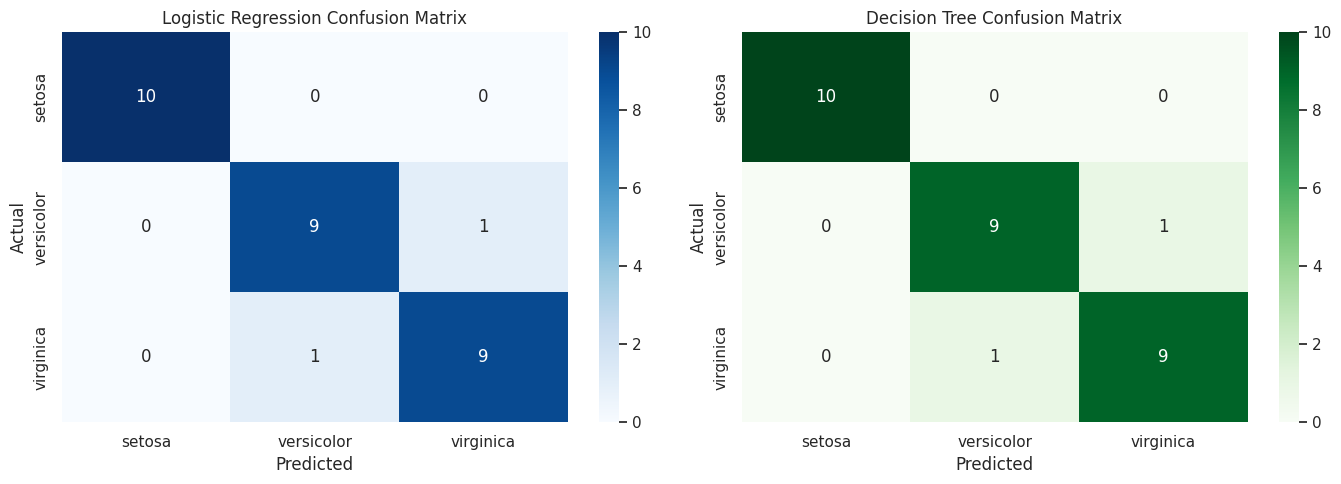

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Logistic Regression
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=Iris.target_names, yticklabels=Iris.target_names)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
#Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=Iris.target_names, yticklabels=Iris.target_names)
axes[1].set_title('Decision Tree Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Decision Boundary visualization

In [29]:
# we will take two properties like (petal lenght & petal width)
X_2d = x[:, 2:4]
y_2d = y

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(X_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d)

scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)
X_test_2d_scaled = scaler_2d.transform(X_test_2d)

In [30]:
#Typically, models are trained on only two properties of the drawing.
clf_lr_2d = LogisticRegression(random_state=42).fit(X_train_2d_scaled, y_train_2d)
clf_dt_2d = DecisionTreeClassifier(random_state=42, max_depth=4).fit(X_train_2d_scaled, y_train_2d)

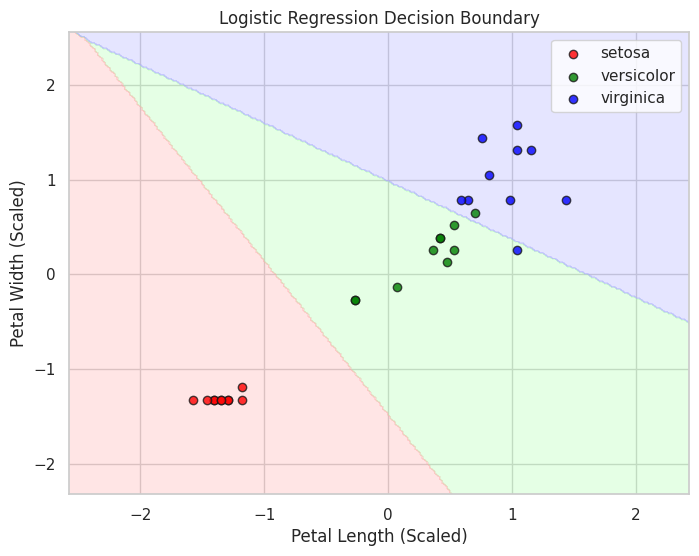

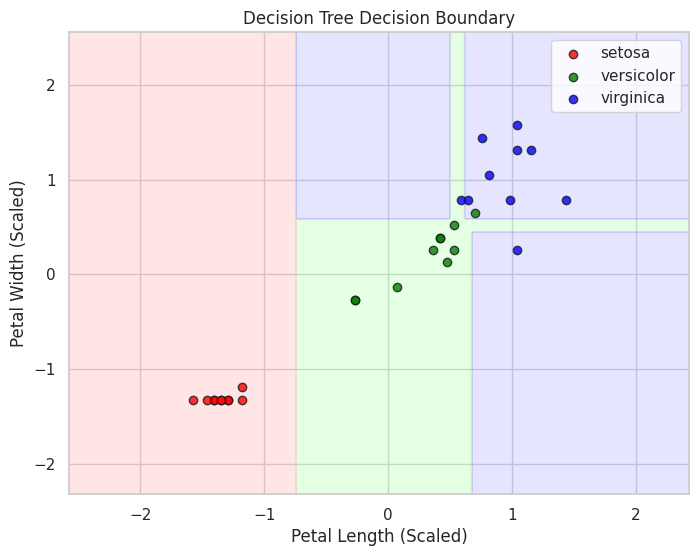

In [32]:
# Decision boundary drawing function
def plot_decision_boundaries(model, X, y, title):
    plt.figure(figsize=(8, 6))
    resolution = 0.02
    cmap_background = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_points = ['red', 'green', 'blue']

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))

    Z = model.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap_background)
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], y=X[y == cl, 1],
                    alpha=0.8, c=cmap_points[idx], marker='o', label=Iris.target_names[cl], edgecolor='k')

    plt.xlabel('Petal Length (Scaled)')
    plt.ylabel('Petal Width (Scaled)')
    plt.title(title)
    plt.legend()
    plt.show()

plot_decision_boundaries(clf_lr_2d, X_test_2d_scaled, y_test_2d, "Logistic Regression Decision Boundary")
plot_decision_boundaries(clf_dt_2d, X_test_2d_scaled, y_test_2d, "Decision Tree Decision Boundary")

Check Models with New Data into array

In [36]:
#  Put the new data into an array (e.g., a flower with 4 properties: length and width of petals and sepals)
new_sample = [[5.1, 3.5, 1.4, 0.2]]

# 2. Apply the same Scaler that was previously trained
# (Very important note: Use only transform and not fit_transform in order for the scales to remain identical)
new_sample_scaled = scaler.transform(new_sample)

# 3. Requesting the prediction from the model (whether Logistic Regression or Decision Tree)
prediction = log_reg.predict(new_sample_scaled)

# 4. Convert the digital result to the flower's real name and display it
predicted_species = Iris.target_names[prediction[0]]
print(f"The type of Flower is : {predicted_species}")

The type of Flower is : versicolor
